# Qwen TorchAO + sim-pruning: training overhead investigation

The original 100-step notebook and its results are preserved in `qlora-Qwen3-30B-A3B_torchao_simpruning.ipynb` / `6_torchao_simpruning_train/torchao_sft_simpruning`.

GPU 2 only; same Qwen checkpoint, FP16 compute / FP32 LoRA, batch 8 × 512, same fixed train/eval blocks, same saved DG mask indices. Each timing variant resets the adapters and optimizer, trains for **6 actual steps**, and evaluates on the same validation subset. Throughput averages steps 3–6, excluding evaluation and preparation. These short speed probes are **not another 100-step convergence experiment**.

Tried: asynchronous RMS correction; HF eager / SDPA attention; skipping empty bridge forwards; avoiding redundant recursive `model.train()`. No custom kernels or package patches. Only measured useful changes should be enabled.

In [1]:
import os, sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ["COMPUTE_DTYPE"] = "fp16"
root = Path.cwd()
while not (root / "lora_transfer_pruning").exists():
    if (root / "LoRa-Transfer-Pruning").exists():
        root = root / "LoRa-Transfer-Pruning"
        break
    if root == root.parent:
        raise RuntimeError("Repository not found")
    root = root.parent
experiment_dir = root / "experiments/qlora"
sys.path.insert(0, str(experiment_dir))
sys.path.insert(0, str(root))
results_dir = experiment_dir / "slop_experiments/7_torchao_simpruing_optimization"


In [2]:
runs = {}
rows, checks = [], []
for folder in ["torchao_sp_optimization", "torchao_sp_optimization_extra"]:
    run = json.loads((results_dir / folder / "benchmark.json").read_text())
    runs[folder] = run
    for r in run["results"]:
        ev = [x for x in r["history"] if "eval_loss" in x][-1]
        rows.append(dict(series=folder, variant=r["name"],
            tokens_per_s=r["tokens_per_second"], samples_per_s=r["samples_per_second"],
            batches_per_s=r["samples_per_second"]/8, step_s=r["step_seconds"],
            peak_GiB=r["peak_GiB"], redundant_train_s=r.get("train_mode_seconds"),
            eval_loss_after_6=ev["eval_loss"], skipped=r["skipped"]))
    checks.extend(dict(series=folder, **x) for x in run["checks"])
table = pd.DataFrame(rows)
display(table)


,series,variant,tokens_per_s,samples_per_s,batches_per_s,step_s,peak_GiB,redundant_train_s,eval_loss_after_6,skipped
0,torchao_sp_optimization,hf_no_sp,792.982744,1.548794,0.193599,5.165308,26.592795,NaN,2.529974,0
1,torchao_sp_optimization,tl_sp_original,413.450241,0.807520,0.100940,9.906875,27.800490,NaN,2.669416,0
2,torchao_sp_optimization,async_rms,405.557927,0.792105,0.099013,10.099667,27.796796,NaN,2.669416,0
3,torchao_sp_optimization,native_sdpa,408.872856,0.798580,0.099822,10.017784,26.603976,NaN,2.669866,0
4,torchao_sp_optimization,native_sdpa_async_rms,413.541577,0.807698,0.100962,9.904687,26.602469,NaN,2.669877,0
5,torchao_sp_optimization_extra,hf_no_sp,793.342225,1.549497,0.193687,5.162967,26.592500,0.133830,2.529963,0
6,torchao_sp_optimization_extra,tl_sp_original,447.324054,0.873680,0.109210,9.156673,27.800490,2.539008,2.669416,0
7,torchao_sp_optimization_extra,cached_train,616.069181,1.203260,0.150408,6.648604,27.800490,0.000003,2.669416,0
8,torchao_sp_optimization_extra,cached_train_native_eager,617.667765,1.206382,0.150798,6.631397,27.802493,0.000003,2.669416,0
9,torchao_sp_optimization_extra,cached_train_native_sdpa,624.356771,1.219447,0.152431,6.560352,26.602698,0.000005,2.669860,0


## Paired measurements

Use the HF and original-SP controls **from the same series**. Timing variability is visible between series; profiler time is not throughput. `redundant_train_s` times an already-training model, not a real mode transition.

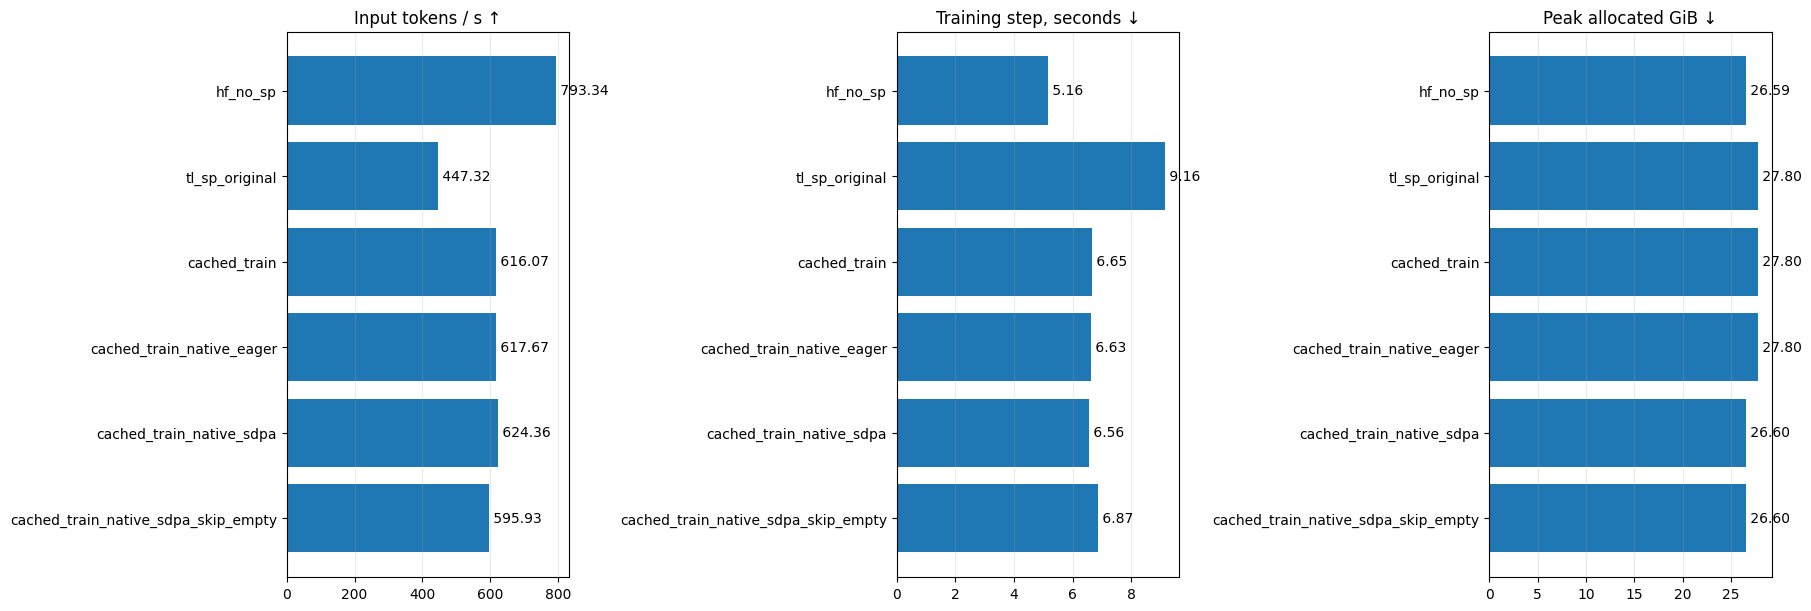

In [3]:
paired = table[table.series == "torchao_sp_optimization_extra"].copy()
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, column, title in zip(axes, ["tokens_per_s", "step_s", "peak_GiB"],
                           ["Input tokens / s ↑", "Training step, seconds ↓", "Peak allocated GiB ↓"]):
    ax.barh(paired.variant, paired[column])
    ax.set_title(title)
    ax.grid(axis="x", alpha=.25)
    ax.invert_yaxis()
    for i, value in enumerate(paired[column]):
        ax.text(value, i, f" {value:.2f}", va="center")
plt.show()


## Numerical checks

Fixed 1 × 128 tokens at the same initial LoRA weights. Compare logits and all adapter gradients (loss scaled by 1024 in both cases). Zero deltas prove equality on this probe, not universally for every input. Native eager matches TL eager here; SDPA does not give bitwise-identical logits/gradients, even when NLL stays close. For the empty-bridge test the reference is native SDPA, as indicated in the table.

In [4]:
display(pd.DataFrame(checks))
smoke = json.loads((results_dir / "torchao_sp_fast_smoke/training.json").read_text())
display(smoke["setup"]["pruning"])
display({k: smoke[k] for k in ["steady_tokens_per_second", "steady_samples_per_second",
    "peak_allocated_GiB", "finite_train_metrics", "skipped_updates", "adapter_check"]})
display(pd.DataFrame([smoke["before"], smoke["after"]], index=["SP before", "After 6 steps"])[
    ["step", "eval_loss", "eval_perplexity", "eval_mean_token_accuracy"]])


,series,name,ref_loss,loss,logits_max_abs,logits_rel_l2,gradient_max_abs,gradient_rel_l2,finite,reference
0,torchao_sp_optimization,async_rms,3.209470,3.209470,0.000000,0.000000,0.00000,0.000000,True,NaN
1,torchao_sp_optimization,native_sdpa,3.209470,3.210561,4.472656,0.026801,1.84375,0.035799,True,NaN
2,torchao_sp_optimization,native_sdpa_async_rms,3.209470,3.210561,4.472656,0.026801,1.84375,0.035799,True,NaN
3,torchao_sp_optimization_extra,cached_train,3.209470,3.209470,0.000000,0.000000,0.00000,0.000000,True,tl_sp_original
4,torchao_sp_optimization_extra,cached_train_native_eager,3.209470,3.209470,0.000000,0.000000,0.00000,0.000000,True,tl_sp_original
5,torchao_sp_optimization_extra,cached_train_native_sdpa,3.209470,3.210561,4.472656,0.026801,1.84375,0.035799,True,tl_sp_original
6,torchao_sp_optimization_extra,cached_train_native_sdpa_skip_empty,3.210561,3.210561,0.000000,0.000000,0.00000,0.000000,True,cached_train_native_sdpa


{'source_plan': '/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/6_torchao_simpruning/torchao_sft_simpruning/pruning_plan.json',
 'mask_audit': {'checked_root_hooks': 387,
  'max_removed_activation': 0.0,
  'hf_peft_probe_loss': 3.9960732460021973},
 'optimization': {'skip_redundant_train': True,
  'attention': 'unchanged TL eager',
  'rmsnorm': 'unchanged dynamic correction',
  'logits_max_abs': 0.0,
  'gradient_max_abs': 0.0}}

{'steady_tokens_per_second': 594.9168826705908,
 'steady_samples_per_second': 1.1619470364659976,
 'peak_allocated_GiB': 27.794920444488525,
 'finite_train_metrics': True,
 'skipped_updates': 0,
 'adapter_check': {'parameter_tensors': 2328,
  'changed_tensors': 2136,
  'max_abs_update': 0.0006057193968445063}}

,step,eval_loss,eval_perplexity,eval_mean_token_accuracy
SP before,0,2.756535,15.745185,0.486057
After 6 steps,6,2.669416,14.431545,0.489543


## Minimal retained change

`Trainer.training_step()` calls `model.train()` every step. TL's registered module graph has shared references; recursive mode setting revisits subtrees. In this setup the repeated call took about 2.54 s versus 0.13 s without TL.

The retained shortcut avoids only **redundant mode recursion**. It still invokes the original method on real train/eval transitions. Eager attention, all hooks, RMS correction, precision and masks remain unchanged.

**Assumption:** during this training loop, child modes change only through the root model. Restore the original method before independently toggling child modules. Do not make this a global PyTorch patch.

In [5]:
# Apply AFTER TL/SP preparation; initialize all child modes consistently.
# from experiments.qlora.torchao_exploration.optimize_qwen_simpruning import skip_redundant_train
# original_train = skip_redundant_train(model)
# trainer.train()
# object.__setattr__(model, "train", original_train)  # restore normal behavior

from experiments.qlora.torchao_exploration.optimize_qwen_simpruning import skip_redundant_train
import inspect
print(inspect.getsource(skip_redundant_train))


Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


def skip_redundant_train(model):
    """Opt-in for this trainer: children change mode only via the root model.

    Still run the original recursive train/eval on every actual mode transition.
    Return the original method for restoring normal behavior after training.
    """
    original_train = model.train
    original_train(True)  # Synchronize all children before enabling the shortcut.

    def train(mode=True):
        if model.training != mode:
            original_train(mode)
        return model

    object.__setattr__(model, 'train', train)
    return original_train



## Profiles

Open the `.chrome.json` files with Chrome/Perfetto. The gzip files are smaller for download. CUDA profiles use a warmed forward/backward/AdamW step; Python mode recursion is measured separately in the timing table and by cProfile on a real Trainer.training_step. Inclusive operator durations overlap and must not be summed as wall time.

In [6]:
paths = [
    results_dir / "torchao_sp_optimization/original_b8_s512.chrome.json.gz",
    results_dir / "torchao_sp_optimization/optimized_b8_s512.chrome.json.gz",
    results_dir / "torchao_sp_optimization_extra/optimized_b8_s512.chrome.json.gz",
    results_dir / "torchao_sp_fast_smoke/training_step.pstats",
]
for path in paths:
    print(path, f"({path.stat().st_size/2**20:.1f} MiB)" if path.exists() else "(not recorded)")
profile_text = results_dir / "torchao_sp_fast_smoke/python_profile.txt"
if profile_text.exists():
    print("\n".join(profile_text.read_text().splitlines()[:40]))


/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/7_torchao_simpruing_optimization/torchao_sp_optimization/original_b8_s512.chrome.json.gz (19.6 MiB)
/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/7_torchao_simpruing_optimization/torchao_sp_optimization/optimized_b8_s512.chrome.json.gz (19.7 MiB)
/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/7_torchao_simpruing_optimization/torchao_sp_optimization_extra/optimized_b8_s512.chrome.json.gz (19.6 MiB)
/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/7_torchao_simpruing_optimization/torchao_sp_fast_smoke/training_step.pstats (0.1 MiB)
         20992833 function calls (18318661 primitive calls) in 13.415 seconds

   Ordered by: internal time
   List reduced from 477 to 60 due to restriction <60>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
   815833    1.422    0.000    3.454    0.000 /glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch/nn/modules/module.py:1969(__setattr_

## Optional full training

Defaults to viewing saved measurements. The command below starts a new 100-step run with the retained optimization; it does not overwrite the original experiment. The fixed mask manifest was generated with LocalPruning. If the checkpoint or prune task changes, rebuild the groups/manifest first; do not replay old indices on a different model.

In [7]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    import subprocess
    subprocess.run([sys.executable, str(experiment_dir / "slop_experiments/train_qwen_torchao_simpruning_fast.py"),
                    "--steps", "100"], cwd=root, env=os.environ.copy(), check=True)
